### Data 620 - Week Eight Assignment
####Text Mining: High-Frequency Words and Word Association

Please answer the following questions in an IPython Notebook, posted to GitHub.
1. Choose a corpus of interest.
2. How many total unique words are in the corpus? (Please feel free to define unique words in any interesting, defensible way).
3. Taking the most common words, how many unique words represent half of the total words in the corpus?
4. Identify the 200 highest frequency words in this corpus.
5. Create a graph that shows the relative frequency of these 200 words.
6. Does the observed relative frequency of these words follow Zipf’s law? Explain.
7. In what ways do you think the frequency of the words in this corpus differ from “all words in all corpora.”

#### Introduction

For the Week 8 assignment, I analyze word frequency in a corpus of five public health articles published by the World Health Organization (WHO). The articles cover topics including disease prevention, vaccines, cancer, and public health. The aim is to examine the vocabulary used in public health communication and investigate whether the distribution of word frequencies follows Zipf’s law.

The analysis measures the number of unique words in the corpus, determines how many of the most frequent words account for half of all word tokens, identifies the 200 most frequent words, and visualizes their relative frequencies. It also considers how the vocabulary and word-frequency distribution of public health articles may differ from those found in a broader collection of texts.

Before analysis, all text is converted to lowercase, and punctuation and numbers are excluded from the primary analysis. Stopwords are retained because common grammatical words contribute to the overall word-frequency distribution and are relevant to evaluating Zipf’s law. A unique word is defined as a distinct lowercase alphabetic token. The corpus is limited to five WHO articles, so the results describe this selected collection rather than public health writing or language as a whole.

#### Install and import the tools

Here I install and import the necessary libraries for this project.

In [14]:
#!pip install requests beautifulsoup4 pandas matplotlib nltk wordcloud

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import time

from bs4 import BeautifulSoup
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from nltk import FreqDist
from nltk.tokenize import RegexpTokenizer
from wordcloud import WordCloud

pd.set_option("display.max_colwidth", 100)

#### Corpus Selection and Article Manifest

For this project, I selected five World Health Organization (WHO) articles about vaccines and cancer prevention to create a public health corpus. Each article’s source, title, and URL are stored in a Python list of dictionaries, which is then converted into a pandas dataframe.

The resulting dataframe contains five rows and three columns: source, title, and URL. This article manifest organizes the corpus sources and provides a reference for collecting and processing the article text in the next stage of the analysis.

In [15]:
# Select the corpus: Public Health Data

articles = [
    {
        "source": "WHO",
        "title": "How Do Vaccines Work?",
        "url": "https://www.who.int/news-room/feature-stories/detail/how-do-vaccines-work"},
    {
        "source": "WHO",
        "title": "Vaccine Efficacy, Effectiveness and Protection",
        "url": "https://www.who.int/news-room/feature-stories/detail/vaccine-efficacy-effectiveness-and-protection"},
    {
        "source": "WHO",
        "title": "Ensuring Vaccine Safety",
        "url": "https://www.who.int/news-room/feature-stories/detail/safety-of-covid-19-vaccines"},
    {
        "source": "WHO",
        "title": "Counting the Impact of Vaccines",
        "url": "https://www.who.int/news-room/feature-stories/detail/counting-the-impact-of-vaccines"},
    {
        "source": "WHO",
        "title": "Four in Ten Cancer Cases Could Be Prevented Globally",
        "url": "https://www.who.int/news/item/03-02-2026-four-in-ten-cancer-cases-could-be-prevented-globally"
    }
]

article_manifest = pd.DataFrame(articles)
article_manifest[["source", "title", "url"]]

,source,title,url
0,WHO,How Do Vaccines Work?,https://www.who.int/news-room/feature-stories/detail/how-do-vaccines-work
1,WHO,"Vaccine Efficacy, Effectiveness and Protection",https://www.who.int/news-room/feature-stories/detail/vaccine-efficacy-effectiveness-and-protection
2,WHO,Ensuring Vaccine Safety,https://www.who.int/news-room/feature-stories/detail/safety-of-covid-19-vaccines
3,WHO,Counting the Impact of Vaccines,https://www.who.int/news-room/feature-stories/detail/counting-the-impact-of-vaccines
4,WHO,Four in Ten Cancer Cases Could Be Prevented Globally,https://www.who.int/news/item/03-02-2026-four-in-ten-cancer-cases-could-be-prevented-globally


#### Downloading and Extracting Article Text

This step downloads the five WHO articles and extracts their text using the Requests and BeautifulSoup libraries. The code includes retry attempts for selected HTTP errors, removes unnecessary webpage elements, and stores the extracted text and article metadata in a pandas DataFrame. It also calculates the raw word count for each article based on whitespace-separated text.

All five articles returned non-empty text, with zero failed or empty downloads. The raw word counts were 1,167, 560, 876, 608, and 617, respectively. These results provide an initial overview of the collected text. The next step is to tokenize and clean the text consistently before conducting the word-frequency analysis.

In [16]:
# Download and extract article title

session = requests.Session()

retry_strategy = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"])

session.mount("https://", HTTPAdapter(max_retries=retry_strategy))

def extract_article_text(url):
    headers = {
        "User-Agent": "Mozilla/5.0 (compatible; AcademicResearch/1.0)",
        "Accept-Language": "en-US,en;q=0.9"
    }

    try:
        response = session.get(
            url,
            headers=headers,
            timeout=30
        )
        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        for element in soup([
            "script", "style", "nav", "footer",
            "header", "aside", "noscript", "form"
        ]):
            element.decompose()

        main = soup.find("main") or soup.find("article") or soup.body

        if main is None:
            return ""

        elements = main.find_all(["p", "h1", "h2", "h3"])

        return " ".join(
            element.get_text(" ", strip=True)
            for element in elements
        )

    except requests.RequestException as error:
        print(f"Download failed: {url}")
        print(error)
        return ""

article_texts = []

for article in articles:
    print("Downloading:", article["title"])

    text = extract_article_text(article["url"])

    article_texts.append({
        "source": article["source"],
        "title": article["title"],
        "url": article["url"],
        "text": text
    })

    time.sleep(1)

corpus_df = pd.DataFrame(article_texts)
corpus_df["text"] = corpus_df["text"].fillna("")

# Exclude documents with failed or empty downloads
corpus_df = corpus_df[
    corpus_df["text"].str.strip().ne("")
].copy().reset_index(drop=True)

corpus_df["word_count_raw"] = (
    corpus_df["text"].str.split().str.len()
)

print("\nSuccessfully retrieved articles:", len(corpus_df))
print("Failed/empty articles:", len(articles) - len(corpus_df))

display(corpus_df[["source", "title", "word_count_raw"]])

if corpus_df.empty:
    raise ValueError(
        "No articles downloaded successfully. "
    )



Downloading: How Do Vaccines Work?
Downloading: Vaccine Efficacy, Effectiveness and Protection
Downloading: Ensuring Vaccine Safety
Downloading: Counting the Impact of Vaccines
Downloading: Four in Ten Cancer Cases Could Be Prevented Globally

Successfully retrieved articles: 5
Failed/empty articles: 0


,source,title,word_count_raw
0,WHO,How Do Vaccines Work?,1167
1,WHO,"Vaccine Efficacy, Effectiveness and Protection",560
2,WHO,Ensuring Vaccine Safety,876
3,WHO,Counting the Impact of Vaccines,608
4,WHO,Four in Ten Cancer Cases Could Be Prevented Globally,617


#### Tokenization and Word Normalization

In this step, I tokenize the extracted text from all five articles using a regular expression that identifies alphabetic sequences. All tokens are converted to lowercase, while punctuation and numbers are excluded. Common words, including stopwords, are retained to preserve the overall word-frequency distribution.

The tokens from all five articles are combined into a single list, and NLTK's FreqDist is used to calculate word frequencies. The total number of tokens (total_tokens) represents all word occurrences in the corpus, while the number of unique types (unique_types) represents the distinct lowercase alphabetic tokens. These measures provide the basis for examining vocabulary size and word-frequency patterns.

In [17]:
# Tokenization and word normalization

# Definition: alphabetic sequences, converted to lowercase.
# Punctuation and numbers are excluded; stopwords are retained.

tokenizer = RegexpTokenizer(r"[A-Za-z]+")
tokens = []

for text in corpus_df["text"]:
    tokens.extend(
        word.lower()
        for word in tokenizer.tokenize(text))

if not tokens:
    raise ValueError("The downloaded articles contained no usable word tokens.")

fdist = FreqDist(tokens)
total_tokens = len(tokens)
unique_types = len(set(tokens))

#### Total Unique Words in the Corpus

This step calculates the total number of word tokens, the number of unique word types, and the type-token ratio (TTR) for the combined corpus. Word tokens represent all word occurrences, while unique word types represent distinct lowercase alphabetic tokens, following the tokenization rules established earlier.

The corpus contains 3,790 word tokens and 1,034 unique word types. The type-token ratio is approximately 0.2728, or 27.28%, calculated by dividing the number of unique word types by the total number of tokens. This provides a descriptive measure of vocabulary diversity in the selected collection of five WHO articles.

In [18]:
# 2. How many total unique words are in the corpus? (Please feel free to define unique words in any interesting,defensible way).

print(f"Total word tokens: {total_tokens:,}")
print(f"Total unique word types: {unique_types:,}")
print(f"Type-token ratio: {unique_types / total_tokens:.4f}")

Total word tokens: 3,790
Total unique word types: 1,034
Type-token ratio: 0.2728


#### Most Common Words Accounting for Half the Corpus

In this step, I rank all unique word types by frequency and calculate their cumulative relative frequency. I then identify the smallest number of the most frequent word types needed to account for at least 50% of all word tokens in the corpus.

The results show that the 77 most frequent word types account for 50.05% of the 3,790 word tokens. This suggests that word occurrences are concentrated among a relatively small portion of the vocabulary, while the remaining word types collectively account for the other half of the corpus.

In [19]:
# 3. Taking the most common words, how many unique words represent half of the total words in the corpus?

frequency_table = pd.DataFrame(
    fdist.most_common(),
    columns=["word", "count"])

frequency_table["relative_frequency"] = (
    frequency_table["count"] / total_tokens)

frequency_table["cumulative_count"] = (
    frequency_table["count"].cumsum())

frequency_table["cumulative_frequency"] = (
    frequency_table["cumulative_count"] / total_tokens)

frequency_table["relative_frequency_percent"] = (
    frequency_table["relative_frequency"] * 100)

half_index = frequency_table[
    frequency_table["cumulative_frequency"] >= 0.50
].index[0]

words_for_half = half_index + 1
half_coverage = frequency_table.loc[
    half_index, "cumulative_frequency"]

print(
    f"The {words_for_half} most frequent unique word types "
    f"account for {half_coverage:.2%} of all word tokens.")

The 77 most frequent unique word types account for 50.05% of all word tokens.


#### Identifying the 200 Most Frequent Words

This step selects the 200 most frequent word types from the complete frequency table and assigns each word a rank from 1 to 200. The table includes each word's count, relative frequency, and cumulative frequency, providing the data needed to visualize the word-frequency distribution and examine Zipf's law.

The most frequent word is “the,” with 178 occurrences (4.70% of all tokens), followed by “and,” with 155 occurrences (4.09%). The 200th-ranked word, “infected,” appears four times. Together, the top 200 word types account for approximately 67.70% of all 3,790 word tokens, demonstrating that a relatively small portion of the vocabulary accounts for a substantial share of the corpus.

In [20]:
# Identify the 200 highest frequency words in this corpus

top_200 = frequency_table.head(200).copy()
top_200.index = range(1, len(top_200) + 1)
top_200.index.name = "rank"

display(top_200)

,word,count,relative_frequency,cumulative_count,cumulative_frequency,relative_frequency_percent
rank,,,,,,
1,the,178,0.046966,178,0.046966,4.696570
2,and,155,0.040897,333,0.087863,4.089710
3,to,115,0.030343,448,0.118206,3.034301
4,of,92,0.024274,540,0.142480,2.427441
5,in,81,0.021372,621,0.163852,2.137203
...,...,...,...,...,...,...
196,include,4,0.001055,2550,0.672823,0.105541
197,age,4,0.001055,2554,0.673879,0.105541
198,three,4,0.001055,2558,0.674934,0.105541


#### Word Cloud of WHO Public Health Articles

This step creates a word cloud using the word frequencies calculated from the five WHO articles. Words that occur more frequently appear larger, providing a visual overview of the vocabulary used throughout the corpus.

The word cloud highlights terms such as “vaccine,” “vaccines,” “health,” “vaccinated,” and “diseases,” reflecting the corpus's focus on vaccination and disease prevention. Other prominent terms, including “safety,” “effective,” “protection,” “children,” and “people,” relate to vaccine effectiveness and public health. Although a word cloud does not show the context in which words are used, it provides a useful visual summary of recurring vocabulary and complements the numerical frequency analysis.

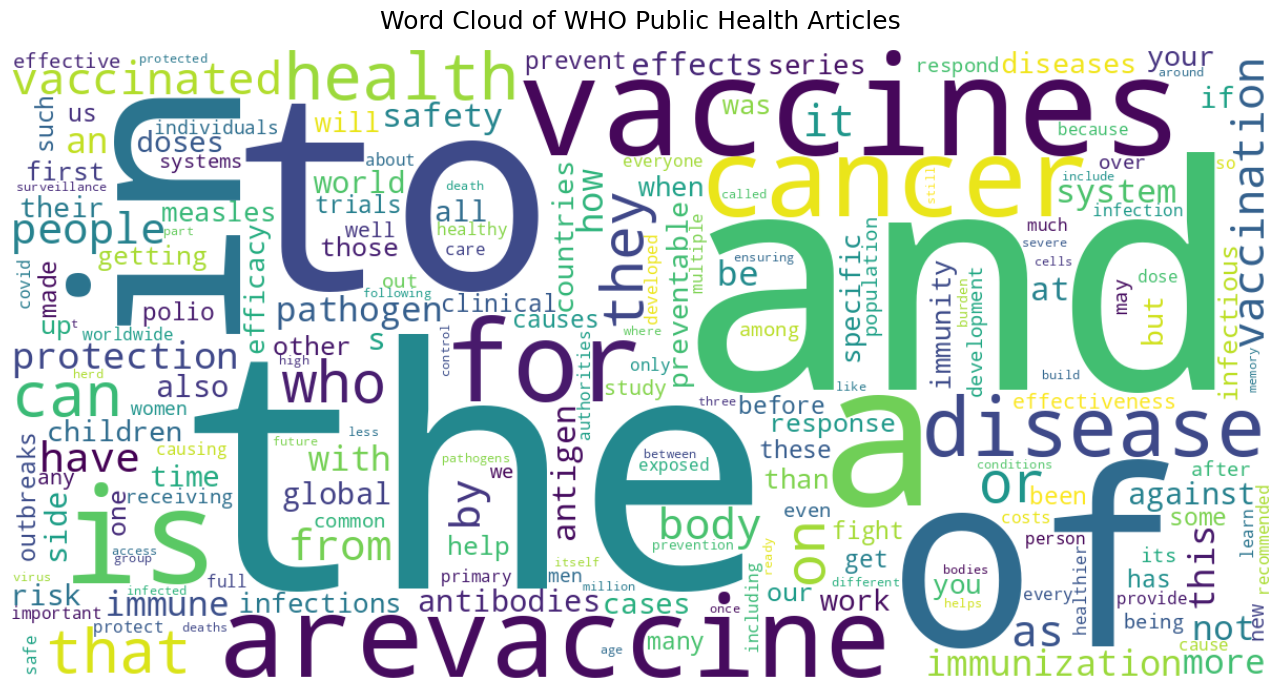

In [29]:
# Use the word frequencies already calculated in your notebook
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis",
    max_words=200,
    prefer_horizontal=0.9,
    collocations=False
).generate_from_frequencies(fdist)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title(
    "Word Cloud of WHO Public Health Articles",
    fontsize=18,
    pad=15
)
plt.tight_layout()
plt.show()

#### Relative Frequencies of the 200 Most Common Words

This code creates a line graph showing the relative frequencies of the 200 most common words, ranked from highest to lowest frequency. lative frequency is calculated by dividing each word's count by the total number of word tokens in the corpus. The graph helps visualize how word usage is distributed across the corpus and how frequently the most common words appear compared with less frequent words.

The graph shows a sharp decline in relative frequency from the highest-ranked words, such as “the,” “and,” and “to,” to less frequent words. This indicates that a small number of words account for a substantial proportion of all word occurrences. The observed pattern is consistent with the general rank-frequency relationship described by Zipf’s law. However, a log-log plot would provide a more informative visual assessment of whether the distribution approximately follows the power-law pattern predicted by Zipf’s law.

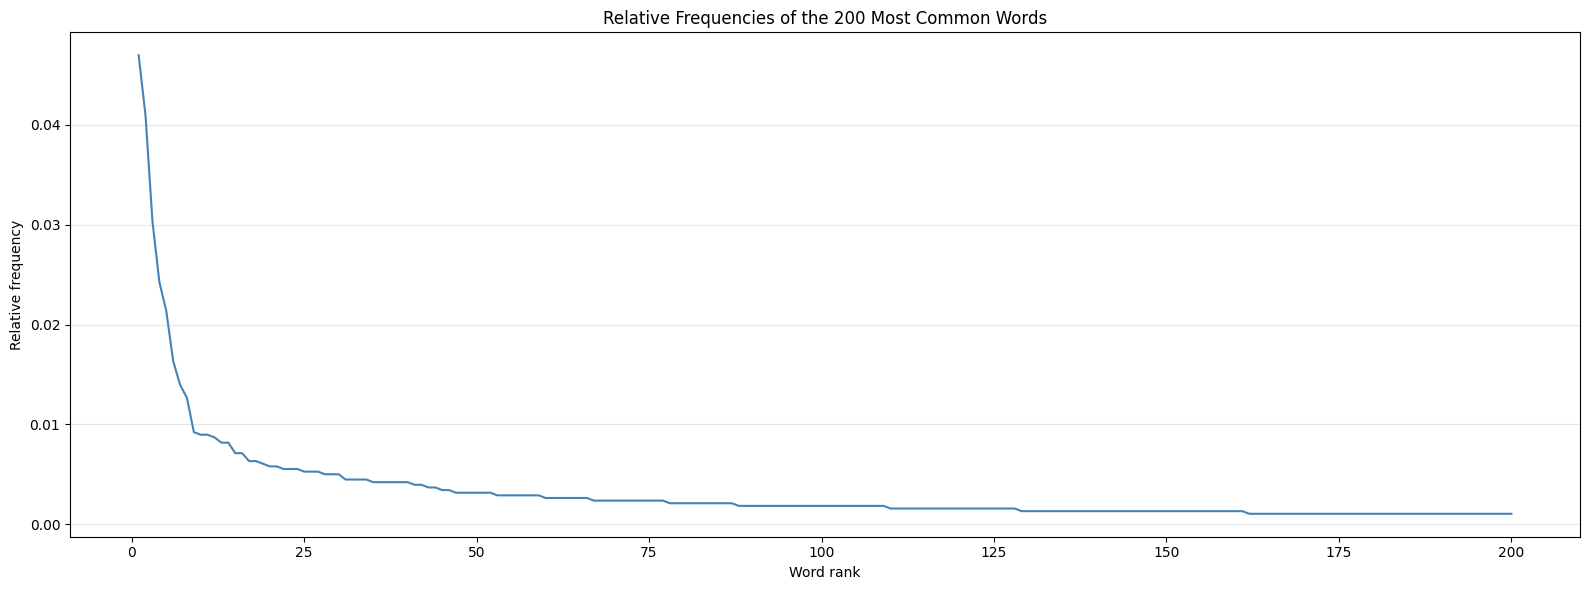

In [30]:
# Create a graph that shows the relative frequency of these 200 words.

plt.figure(figsize=(16, 6))

plt.plot(
    range(1, len(top_200) + 1),
    top_200["relative_frequency"],
    color="steelblue",
    linewidth=1.5
)

plt.title("Relative Frequencies of the 200 Most Common Words")
plt.xlabel("Word rank")
plt.ylabel("Relative frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Testing Zipf’s Law

To examine whether the corpus follows Zipf’s law, I created a log-log plot of word frequency against word rank and estimated the slope of the relationship using linear regression on the logarithmically transformed values. Zipf’s law predicts an approximate inverse relationship between word rank and frequency, corresponding to a slope near −1 on a log-log plot.

The graph shows a general downward trend: high-ranking words occur frequently, while many lower-ranking words occur only a few times. The estimated log-log slope is −0.883, which is relatively close to the theoretical reference value of −1. This suggests that the word-frequency distribution of the five WHO articles is broadly consistent with a Zipf-like pattern, although it does not follow the ideal relationship exactly. The deviations may reflect the limited size and specialized subject matter of the corpus, as well as natural variation in word usage. The slope provides useful evidence, but the overall shape of the graph should also be considered when interpreting the results.

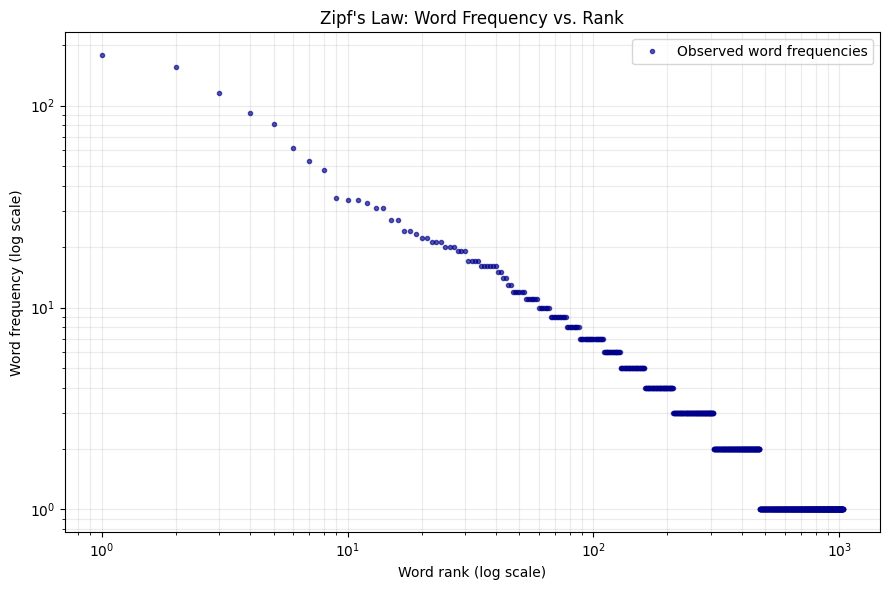

Estimated log-log slope: -0.883
Reference slope for Zipf's law: approximately -1


In [31]:
# Does the observed relative frequency of these words follow Zipf’s law? Explain.

ranks = np.arange(1, len(frequency_table) + 1)
counts = frequency_table["count"].to_numpy()

plt.figure(figsize=(9, 6))

plt.loglog(
    ranks,
    counts,
    marker=".",
    linestyle="none",
    color="darkblue",
    alpha=0.65,
    label="Observed word frequencies")

plt.title("Zipf's Law: Word Frequency vs. Rank")
plt.xlabel("Word rank (log scale)")
plt.ylabel("Word frequency (log scale)")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

if len(counts) >= 2:
    slope, intercept = np.polyfit(
    np.log10(ranks),
    np.log10(counts),
    1)

print(f"Estimated log-log slope: {slope:.3f}")
print("Reference slope for Zipf's law: approximately -1")


#### How Does This Corpus Differ from “All Words in All Corpora”?

The word-frequency distribution in my corpus is likely to differ from that of a general collection of texts because the five articles focus on public health, vaccines, disease prevention, and cancer. Topic-specific words such as “vaccine,” “vaccines,” “health,” and “disease” are likely to occur more frequently in this corpus than in texts about unrelated subjects, such as fiction, sports, or entertainment.

The formal and informational style of WHO articles may also influence word frequencies. Terms related to prevention, safety, effectiveness, and protection are important to communicating public health information. At the same time, common grammatical words such as “the,” “and,” and “to” remain frequent. In my corpus, “the” is the most frequent word, followed by “and,” illustrating the importance of common words in the overall frequency distribution.

However, my corpus contains only five articles from a single organization, so it cannot represent all English-language writing. A larger and more diverse corpus would include different topics, genres, writing styles, and audiences, potentially producing a different frequency distribution. Therefore, although my results illustrate common patterns in word frequency, the specific words and their relative frequencies are influenced by the subject matter and composition of my selected corpus.

#### Final Summary and Conclusion

This analysis examined five WHO public health articles containing 3,790 word tokens and 1,034 unique word types. The results showed that the 77 most frequent word types accounted for approximately half of all word occurrences, demonstrating that word usage is concentrated among the most frequent words. The relative-frequency graph showed a sharp decline followed by a gradual flattening, while the estimated log-log slope of −0.883 suggested a distribution broadly consistent with Zipf’s law. These findings reflect the frequent use of common English words alongside specialized vocabulary related to vaccination, disease prevention, and public health.

However, because the corpus contains only five articles from one organization, its word-frequency patterns may differ from those of larger and more diverse text collections. Overall, this project demonstrates how word-frequency analysis and visualization can reveal patterns in language and provide insight into the vocabulary used in public health communication.

In [23]:
print(f"Articles analyzed: {len(corpus_df)}")
print(f"Total word tokens: {total_tokens:,}")
print(f"Unique word types: {unique_types:,}")
print(f"Word types accounting for at least half the corpus: {words_for_half}")
print(f"Number of words in top-200 table: {len(top_200)}")

if len(counts) >= 2:
    print(f"Estimated Zipf log-log slope: {slope:.3f}")

Articles analyzed: 5
Total word tokens: 3,790
Unique word types: 1,034
Word types accounting for at least half the corpus: 77
Number of words in top-200 table: 200
Estimated Zipf log-log slope: -0.883
